The **SIR model** is a classical mathematical model used in epidemiology to describe the spread of infectious diseases.It remains a fundamental tool in epidemiology for understanding disease dynamics, informing public health policies, and predicting epidemic outcomes.

It divides the population into three compartments:

1. **S (Susceptible)**: Individuals who are not yet infected but are at risk of becoming infected.
2. **I (Infected)**: Individuals who are currently infected and can spread the disease to susceptible individuals.
3. **R (Recovered or Removed)**: Individuals who have recovered from the disease and are now immune, or have been removed from the population (due to isolation, death, etc.).

### Model Dynamics
The SIR model uses differential equations to describe the flow of individuals between these compartments over time:

- **Susceptibles** ($ S(t) $): As the disease spreads, susceptible individuals come into contact with infected individuals and transition to the infected group. This is controlled by a transmission rate ($ \beta $).
  
  $
  \frac{dS}{dt} = -\beta S I
  $

- **Infected** ($ I(t) $): The infected population grows as susceptible individuals get infected, and decreases as infected individuals recover or are removed. This is controlled by the transmission rate ($ \beta $) and a recovery rate ($ \gamma $).
  
  $
  \frac{dI}{dt} = \beta S I - \gamma I
  $

- **Recovered/Removed** ($ R(t) $): The recovered population increases as infected individuals recover or are removed from the population. The rate of recovery is controlled by the recovery rate ($ \gamma $).
  
  $
  \frac{dR}{dt} = \gamma I
  $

### Key Parameters:
- **Transmission rate ($ \beta $)**: The rate at which an infected individual can transmit the disease to a susceptible individual.
- **Recovery rate ($ \gamma $)**: The rate at which infected individuals recover, become immune or are removed from the population.
- **Basic reproduction number ($ R_0 $)**: This is a critical threshold in epidemiology, defined as $ R_0 = \frac{\beta}{\gamma} $, which represents the average number of secondary infections produced by one infected individual. If $ R_0 > 1 $, the disease can spread in the population, while $ R_0 < 1 $ suggests the disease will eventually die out.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [61]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import random
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import load_model, Model
from sklearn.metrics import r2_score
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler
from tensorflow.keras.callbacks import Callback

### Simulating the SIR Model for Multiple Transmission Rates with uniform noise

1. We use the SIR model (no exposed or mosquito populations, so we will only work with three equations: $ \frac{dS_h}{dt}, \frac{dI_h}{dt}, and \frac{dR_h}{dt}$.

2. The transmission rate $\beta$ will have uniform noise added between \([0,1]\).


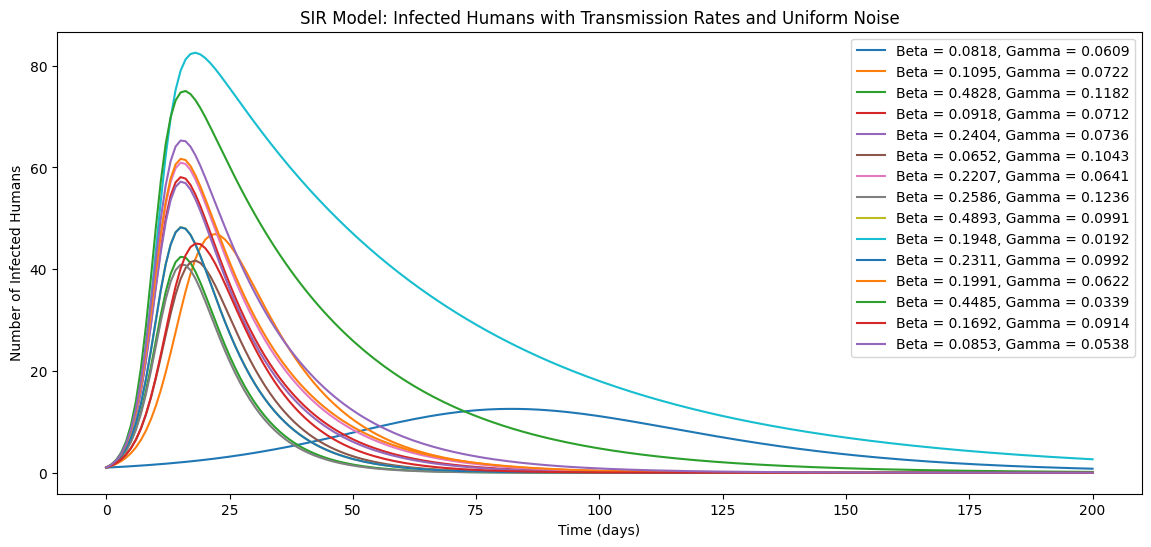

In [62]:
# SIR model for human population
def sir_model_human(y, t, N_h, beta, gamma):
    S_h, I_h, R_h = y

    # Human equations for SIR model
    dS_h_dt = -beta * S_h * I_h / N_h
    dI_h_dt = beta * S_h * I_h / N_h - gamma * I_h
    dR_h_dt = gamma * I_h

    return [dS_h_dt, dI_h_dt, dR_h_dt]

# Parameters
N_h = 100  # Total human population

# Initial conditions for SIR model
S_h0 = N_h - 1   # Initial susceptible humans
I_h0 = 1         # Initial infected humans
R_h0 = 0         # Initial recovered humans

y0 = [S_h0, I_h0, R_h0]  # Initial condition vector

# Time points (e.g., 200 days)
t = np.linspace(0, 200, 200)

# Transmission rate range with uniform noise added
beta_min = 0.0005
beta_max = 0.5

# Recovery rate range
gamma_min = 1/100
gamma_max = 1/7

# Generate 100 transmission rates and recovery rates with uniform noise between [0, 1]
transmission_rates = np.random.uniform(beta_min, beta_max, 100)
recovery_rates = np.random.uniform(gamma_min, gamma_max, 100)

# Store the results for infected humans over time
infected_time_series = []

# Simulate SIR model for each transmission rate and corresponding recovery rate
for beta, gamma in zip(transmission_rates, recovery_rates):
    # Add uniform noise to beta
    beta_with_noise = beta + np.random.uniform(0, 1)

    # Ensure beta stays within bounds
    beta_with_noise = np.clip(beta_with_noise, beta_min, beta_max)

    result = odeint(sir_model_human, y0, t, args=(N_h, beta_with_noise, gamma))
    S_h, I_h, R_h = result.T  # Get the infected individuals (I_h)
    infected_time_series.append(I_h)

# Plotting the infected humans over time for 15 random transmission rates (SIR)
plt.figure(figsize=(14, 6))
for i in random.sample(range(100), 15):  # Randomly sample 15 beta and gamma values
    plt.plot(t, infected_time_series[i], label=f'Beta = {transmission_rates[i]:.4f}, Gamma = {recovery_rates[i]:.4f}')  # Explicitly label the beta and gamma values
plt.xlabel('Time (days)')
plt.ylabel('Number of Infected Humans')
plt.title('SIR Model: Infected Humans with Transmission Rates and Uniform Noise')
plt.legend()
plt.show()

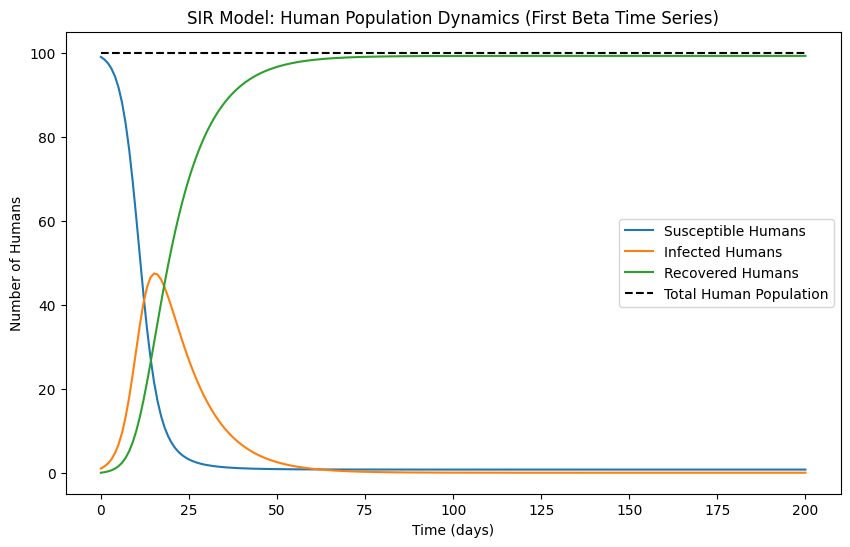

In [63]:
# Calculate total human population over time (S_h + I_h + R_h should always sum to N_h)
total_population = S_h + I_h + R_h

# Plotting susceptible, exposed, infected, recovered humans, and total population
plt.figure(figsize=(10, 6))
plt.plot(t, S_h, label='Susceptible Humans')
plt.plot(t, I_h, label='Infected Humans')
plt.plot(t, R_h, label='Recovered Humans')
plt.plot(t, total_population, label='Total Human Population', linestyle='--', color='black')

plt.title('SIR Model: Human Population Dynamics (First Beta Time Series)')
plt.xlabel('Time (days)')
plt.ylabel('Number of Humans')
plt.legend()
plt.show()

### SIR vs SEIRS


The issue with the SIR plot not showing the same variability in infection dynamics like the SEIRS plot is because the SIR model is much simpler than the SEIRS model.

* In the SIR model, there are only three compartments (Susceptible, Infected, Recovered), and once someone recovers, they cannot become infected again. This tends to lead to a monotonic decrease in the number of infected individuals over time.

*  In contrast, the SEIRS model accounts for exposed individuals and the possibility of losing immunity (moving from Recovered back to Susceptible). This makes the SEIRS model more dynamic, allowing for more pronounced peaks in infection rates. The variation in infection dynamics for different beta values in SEIRS is much more apparent.

* Also, regarding the **beta values**, The beta variation in the SIR model can't be seen as much because the transmission rate is not strongly driving divergent outcomes in such a simple model, especially that the recovery rate is similar across all simulations.

### Saving Combined Time Series to CSV

In [64]:
# We use the generated transmission rates as beta values
beta_values = transmission_rates
gamma_values = recovery_rates

# Combine the time-series data into a single DataFrame
combined_data = infected_time_series
# Include both Beta and Gamma in the column names
combined_df = pd.DataFrame(np.array(combined_data).T, columns=[f'Beta_{beta:.4f}_Gamma_{gamma:.4f}' for beta, gamma in zip(beta_values, gamma_values)])

# Add a column for time
combined_df['Time (days)'] = t

# Save the combined data to CSV for future use
combined_df.to_csv('combined_sir_infected_time_series.csv', index=False)

print('Generated time-series data saved to combined_sir_infected_time_series.csv')
print('Shape of the data:', combined_df.shape)
print(combined_df.head())


Generated time-series data saved to combined_sir_infected_time_series.csv
Shape of the data: (200, 101)
   Beta_0.0158_Gamma_0.0981  Beta_0.1948_Gamma_0.0192  \
0                  1.000000                  1.000000   
1                  1.483351                  1.544912   
2                  2.192244                  2.378969   
3                  3.222504                  3.645113   
4                  4.700103                  5.543296   

   Beta_0.0918_Gamma_0.0712  Beta_0.4336_Gamma_0.0504  \
0                  1.000000                  1.000000   
1                  1.528754                  1.561157   
2                  2.328109                  2.427634   
3                  3.524915                  3.752231   
4                  5.291008                  5.746428   

   Beta_0.4424_Gamma_0.0602  Beta_0.3057_Gamma_0.0688  \
0                  1.000000                  1.000000   
1                  1.545840                  1.532445   
2                  2.380329            

### Loading the Data and Splitting it into Training and Testing

In [65]:
# Load the combined data (100 infection rate time series, 200 time steps)
csv_file = 'combined_sir_infected_time_series.csv'
data = pd.read_csv(csv_file)

# Extract the time-series data (excluding the 'Time (days)' column)
time_series_data = data.drop(columns=['Time (days)']).values  # Shape: (200, 100)

# Split the data into training (70 time-series) and testing (30 time-series)
train_size = int(time_series_data.shape[1] * 0.7)  # 70% of the columns for training
train_data = time_series_data[:, :train_size]  # Shape: (200, 70)
test_data = time_series_data[:, train_size:]   # Shape: (200, 30)

print('Training data:', train_data.shape)
print('Testing data:', test_data.shape)

Training data: (200, 70)
Testing data: (200, 30)


### Normalise the Data

In [66]:
# Normalising each time-series independently for both training and testing data
scalers = {}  # To store scalers for each series

# For each time-series in the training set
train_data_scaled = np.zeros_like(train_data)
for i in range(train_data.shape[1]):  # Loop through each time-series (column)
    scalers[i] = MinMaxScaler(feature_range=(0, 1))  # Create a new scaler for each time-series
    train_data_scaled[:, i] = scalers[i].fit_transform(train_data[:, i].reshape(-1, 1)).flatten()  # Scale each series independently

# Similarly for the test set
test_data_scaled = np.zeros_like(test_data)
for i in range(test_data.shape[1]):  # Loop through each time-series (column)
    test_data_scaled[:, i] = scalers[i].transform(test_data[:, i].reshape(-1, 1)).flatten()  # Scale using the same scaler as for training

### Building the LSTM-SIR models

Building LSTM-SIR with differents layers (1, 2, 3 and 4), 100 hidden units each, and two different epochs ( 10 & 20).

* Layers_list = [1, 2, 3, 4]
* Hidden units_list = [50,100]
* Epochs_list = [10, 20]

### Defining the function to create directories for each model

In [67]:
# Function to create directories for each model
def create_model_directory(model_name):
    if not os.path.exists(model_name):
        os.makedirs(model_name)

# Function to save the training and validation loss plot
def save_loss_plot(history, model_name):
    plt.figure(figsize=(8, 6))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{model_name}: Training and Validation Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.savefig(f'{model_name}/loss_plot_{model_name}.png')
    plt.close()  # Close the plot to save memory

### Defining the function to save model parameters (weights and biases)


We will modify the training process to save the **weights and biases** after each epoch using **Keras Callbacks**.

The **ModelCheckpoint** callback can be used to save the weights, and we will create a custom callback to calculate and save the parameters (weights and biases) as follows:

1. Custom Callback to Save Weights and Biases After Each Epoch:
We will define a custom callback to save weights and biases in the format you specified. This will save them in .csv files after each epoch.

2. Modify the Model Training Process:
We will integrate this callback into the model training process so that the weights and biases are saved after each epoch.

To calculate the number of weights and biases, we will use the **model.count_params()** function for each layer in the model.

In [68]:
# Function to save model parameters (weights and biases)
def save_model_parameters(model, model_name,epoch):
    # Get the weights of the model
    weights = model.get_weights()

    # Create a directory for the model parameters if it doesn't exist
    params_dir = f'{model_name}/parameters_epoch_{epoch}'
    if not os.path.exists(params_dir):
        os.makedirs(params_dir)

    # Save each weight matrix and bias vector
    for i, weight in enumerate(weights):
        # Save each parameter array (weights or biases) to a separate file
        np.savetxt(f'{params_dir}/param_{i}.csv', weight, delimiter=',')

    print(f"Model parameters saved for {model_name} at epoch {epoch}.")

We will add:

1. Custom Callback **SaveModelParamsCallback**:

* This callback saves the model's weights and biases in .csv format after each epoch in the directory structure you prefer.
* It calls **save_model_parameters()** after every epoch during training.

2. Count Model Parameters:

* The **count_model_params()** function is added to calculate and return the total, trainable, and non-trainable parameters for each model.

3. Logging Parameters:

* The results of each model now include the number of total, trainable, and non-trainable parameters, which are saved to the experiment results.

In [69]:
#Custom callback to save weights and biases after each epoch
class SaveModelParamsCallback(Callback):
    def __init__(self, model_name):
        super(SaveModelParamsCallback, self).__init__()
        self.model_name = model_name

    def on_epoch_end(self, epoch, logs=None):
        # Save model parameters at the end of each epoch
        save_model_parameters(self.model, self.model_name, epoch + 1)  # Epoch index starts from 0

# Function to count the number of weights and biases in the model
def count_model_params(model):
    total_params = model.count_params()  # Total parameters (weights + biases)
    trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
    non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])

    return total_params, trainable_params, non_trainable_params

### Defining the function to save MAE, RMSE and R2 for each model

In [70]:
# Function to save MAE, RMSE and R2 for each model
def save_mae_rmse(mae, rmse,r2, model_name):
    with open(f'{model_name}/mae_rmse_r2.txt', 'w') as f:
        f.write(f'MAE: {mae}\n')
        f.write(f'RMSE: {rmse}\n')
        f.write(f'R²: {r2}\n')  # Added R² to the results

# Define a function to save scatter plot for actual vs predicted values
def save_scatter_plot(actual, predicted, model_name, series_num):
    plt.figure(figsize=(6, 6))
    plt.scatter(actual, predicted, c='blue', marker='o')
    plt.plot([min(actual), max(actual)], [min(actual), max(actual)], color='red', linewidth=2)
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title(f'Actual vs Predicted for {model_name} - Series {series_num}')
    plt.savefig(f'{model_name}/scatter_plot_series_{series_num}.png')
    plt.close()

# Defining the LSTM-SIR model with a learning rate = 0.0001

In [71]:
from tensorflow.keras.layers import Dropout

# Build the LSTM-SIR model with a learning rate = 0.0001
def build_lstm_model(layers=1, units=100, look_back=10,learning_rate=0.0001, dropout_rate=0.2):
    model = Sequential()
    model.add(LSTM(units, return_sequences=(layers > 1), input_shape=(look_back, 1)))  # Input for one time-series
    model.add(Dropout(dropout_rate))  # Dropout after the first LSTM layer

    # Additional LSTM layers with Dropout
    for _ in range(1, layers):
        model.add(LSTM(units, return_sequences=(_ != layers - 1)))
        model.add(Dropout(dropout_rate))  # Dropout after each LSTM layer

    # Final Dense layer for output
    model.add(Dense(1))  # Single output for each time-series

    # Compile the model with a learning rate
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mean_squared_error')
    return model

def create_sequences(data, look_back):
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:i + look_back])
        y.append(data[i + look_back])
    return np.array(X), np.array(y)

# Learning rate scheduler
def lr_schedule(epoch, lr):
    if epoch > 10:
        return lr * 0.5  # Decrease the learning rate after 10 epochs
    return lr

In [72]:
# The training loop to save models and plots
def run_experiments(train_data_scaled, test_data_scaled, epochs_list, layers_list, units_list, look_back):
    experiment_results = []

    for epochs in epochs_list:
        for layers in layers_list:
            for units in units_list:
                model_name = f'LSTM-SIR-{layers}_layers-{units}_units-{epochs}_epochs'
                print(f"Training model: {model_name}")

                # Create model directory
                create_model_directory(model_name)

                # Build and compile the model
                model = build_lstm_model(layers, units, look_back,learning_rate=0.0001)

                # Count model parameters (weights and biases)
                total_params, trainable_params, non_trainable_params = count_model_params(model)
                print(f"Model {model_name} has {total_params} total parameters.")
                print(f"Trainable parameters: {trainable_params}, Non-trainable parameters: {non_trainable_params}")

                # Prepare X_train and y_train from train_data_scaled
                X_train, y_train = create_sequences(train_data_scaled.flatten(), look_back)
                X_train = X_train.reshape((X_train.shape[0], look_back, 1))  # Reshaping for LSTM

                # Define callbacks
                save_params_callback = SaveModelParamsCallback(model_name)

                # Set up checkpoints and learning rate schedule
                checkpoint = ModelCheckpoint(f'{model_name}/best_model.keras', monitor='val_loss', save_best_only=True)
                lr_scheduler = LearningRateScheduler(lr_schedule)

                # Train the model on the entire training set
                history = model.fit(X_train, y_train, epochs=epochs, batch_size=32, verbose=2, validation_split=0.2,callbacks=[checkpoint, lr_scheduler])

                # Save the trained model
                model.save(f'{model_name}/model_{model_name}.keras')

                # Save the training and validation loss plot
                save_loss_plot(history, model_name)

                # Test the model on the test set and calculate MAE, RMSE, and R²
                mae_list = []
                rmse_list = []
                r2_list = []
                for i in range(test_data.shape[1]):
                    test_series = test_data_scaled[:, i]
                    X_test_i, y_test_i = create_sequences(test_series, look_back)
                    X_test_i = X_test_i.reshape((X_test_i.shape[0], look_back, 1))

                    # Predict
                    predicted_test_i = model.predict(X_test_i)
                    predicted_test_i_inverse = scalers[0].inverse_transform(predicted_test_i.reshape(-1, 1))
                    y_test_i_inverse = scalers[0].inverse_transform(y_test_i.reshape(-1, 1))

                    # Calculate MAE, RMSE, and R² for the test series
                    mae = mean_absolute_error(y_test_i_inverse, predicted_test_i_inverse)
                    rmse = np.sqrt(mean_squared_error(y_test_i_inverse, predicted_test_i_inverse))
                    r2 = r2_score(y_test_i_inverse, predicted_test_i_inverse) # Calculate R² score

                    mae_list.append(mae)
                    rmse_list.append(rmse)
                    r2_list.append(r2)

                    # Save scatter plot for the current test series
                    save_scatter_plot(y_test_i_inverse, predicted_test_i_inverse, model_name, i+1)

                    # Save model parameters (coefficients) after training on each series
                    save_model_parameters(model, model_name, i+1)  # Save after each series

                # Calculate average MAE, RMSE, and R² across all test series
                average_mae = np.mean(mae_list)
                average_rmse = np.mean(rmse_list)
                average_r2 = np.mean(r2_list)  # Average R² score

                # Save MAE, RMSE, and R² to a file
                save_mae_rmse(average_mae, average_rmse,average_r2, model_name)

                # Append the results to the experiment results list
                experiment_results.append({
                    'Model': model_name,
                    'Epochs': epochs,
                    'Layers': layers,
                    'Units': units,
                    'MAE': average_mae,
                    'RMSE': average_rmse,
                    'R²': average_r2,  # Add R² to the results
                    'Final_Training_Loss': history.history['loss'][-1],  # Final training loss
                    'Final_Validation_Loss': history.history['val_loss'][-1],  # Final validation loss
                    'Total_Params': total_params,  # Add total params to the results
                    'Trainable_Params': trainable_params,
                    'Non_Trainable_Params': non_trainable_params
                })

    return pd.DataFrame(experiment_results)


In [73]:
# Define the parameters for the experiments
epochs_list = [ 10, 20]  # List of epochs to experiment with
layers_list = [1, 2, 3,4]  # Number of LSTM layers
units_list = [100]  # Number of hidden units in each LSTM layer

look_back = 10  # Number of time steps to look back in the input data


# Run the experiments
experiment_results = run_experiments(train_data_scaled,
                                     test_data_scaled,
                                     epochs_list,
                                     layers_list,
                                     units_list,
                                     look_back)


# Save the experiment results to a CSV file
experiment_results.to_csv('experiment_results.csv', index=False)

# Print the experiment results
print(experiment_results)

Training model: LSTM-SIR-1_layers-100_units-10_epochs
Model LSTM-SIR-1_layers-100_units-10_epochs has 40901 total parameters.
Trainable parameters: 40901, Non-trainable parameters: 0.0
Epoch 1/10


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


350/350 - 7s - 21ms/step - loss: 0.0343 - val_loss: 3.8502e-04 - learning_rate: 1.0000e-04
Epoch 2/10
350/350 - 8s - 24ms/step - loss: 0.0253 - val_loss: 3.8332e-04 - learning_rate: 1.0000e-04
Epoch 3/10
350/350 - 4s - 12ms/step - loss: 0.0249 - val_loss: 2.5479e-04 - learning_rate: 1.0000e-04
Epoch 4/10
350/350 - 5s - 13ms/step - loss: 0.0247 - val_loss: 4.5116e-04 - learning_rate: 1.0000e-04
Epoch 5/10
350/350 - 3s - 10ms/step - loss: 0.0246 - val_loss: 2.6824e-04 - learning_rate: 1.0000e-04
Epoch 6/10
350/350 - 4s - 11ms/step - loss: 0.0245 - val_loss: 3.8294e-04 - learning_rate: 1.0000e-04
Epoch 7/10
350/350 - 6s - 16ms/step - loss: 0.0245 - val_loss: 4.0907e-04 - learning_rate: 1.0000e-04
Epoch 8/10
350/350 - 4s - 10ms/step - loss: 0.0244 - val_loss: 3.7804e-04 - learning_rate: 1.0000e-04
Epoch 9/10
350/350 - 7s - 19ms/step - loss: 0.0242 - val_loss: 3.7385e-04 - learning_rate: 1.0000e-04
Epoch 10/10
350/350 - 4s - 12ms/step - loss: 0.0240 - val_loss: 3.6259e-04 - learning_rate: 1

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


350/350 - 13s - 38ms/step - loss: 0.0339 - val_loss: 3.9575e-04 - learning_rate: 1.0000e-04
Epoch 2/10
350/350 - 8s - 22ms/step - loss: 0.0254 - val_loss: 5.8978e-04 - learning_rate: 1.0000e-04
Epoch 3/10
350/350 - 11s - 32ms/step - loss: 0.0252 - val_loss: 6.2185e-04 - learning_rate: 1.0000e-04
Epoch 4/10
350/350 - 10s - 28ms/step - loss: 0.0250 - val_loss: 2.8866e-04 - learning_rate: 1.0000e-04
Epoch 5/10
350/350 - 8s - 24ms/step - loss: 0.0248 - val_loss: 4.3898e-04 - learning_rate: 1.0000e-04
Epoch 6/10
350/350 - 11s - 32ms/step - loss: 0.0248 - val_loss: 4.8286e-04 - learning_rate: 1.0000e-04
Epoch 7/10
350/350 - 9s - 27ms/step - loss: 0.0247 - val_loss: 5.6338e-04 - learning_rate: 1.0000e-04
Epoch 8/10
350/350 - 9s - 25ms/step - loss: 0.0246 - val_loss: 4.4072e-04 - learning_rate: 1.0000e-04
Epoch 9/10
350/350 - 10s - 28ms/step - loss: 0.0246 - val_loss: 4.5362e-04 - learning_rate: 1.0000e-04
Epoch 10/10
350/350 - 10s - 27ms/step - loss: 0.0247 - val_loss: 2.8084e-04 - learning_r

...

Epoch 1/20
350/350 - 11s - 31ms/step - loss: 0.0319 - val_loss: 4.9656e-04 - learning_rate: 1.0000e-04
Epoch 2/20
350/350 - 12s - 33ms/step - loss: 0.0252 - val_loss: 2.5000e-04 - learning_rate: 1.0000e-04
Epoch 3/20
350/350 - 6s - 17ms/step - loss: 0.0251 - val_loss: 5.4984e-04 - learning_rate: 1.0000e-04
Epoch 4/20
350/350 - 10s - 29ms/step - loss: 0.0251 - val_loss: 2.8424e-04 - learning_rate: 1.0000e-04
Epoch 5/20
350/350 - 12s - 33ms/step - loss: 0.0249 - val_loss: 3.6710e-04 - learning_rate: 1.0000e-04
Epoch 6/20
350/350 - 6s - 17ms/step - loss: 0.0248 - val_loss: 4.1223e-04 - learning_rate: 1.0000e-04
Epoch 7/20
350/350 - 8s - 23ms/step - loss: 0.0246 - val_loss: 3.7461e-04 - learning_rate: 1.0000e-04
Epoch 8/20
350/350 - 6s - 17ms/step - loss: 0.0245 - val_loss: 2.9334e-04 - learning_rate: 1.0000e-04
Epoch 9/20
350/350 - 8s - 23ms/step - loss: 0.0245 - val_loss: 4.0673e-04 - learning_rate: 1.0000e-04
Epoch 10/20
350/350 - 8s - 23ms/step - loss: 0.0245 - val_loss: 4.6857e-04 - l

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


350/350 - 19s - 54ms/step - loss: 0.0319 - val_loss: 8.2221e-04 - learning_rate: 1.0000e-04
Epoch 2/20
350/350 - 18s - 51ms/step - loss: 0.0262 - val_loss: 5.1968e-04 - learning_rate: 1.0000e-04
Epoch 3/20
350/350 - 11s - 31ms/step - loss: 0.0260 - val_loss: 3.7461e-04 - learning_rate: 1.0000e-04
Epoch 4/20
350/350 - 11s - 33ms/step - loss: 0.0257 - val_loss: 4.8208e-04 - learning_rate: 1.0000e-04
Epoch 5/20
350/350 - 19s - 55ms/step - loss: 0.0255 - val_loss: 2.3628e-04 - learning_rate: 1.0000e-04
Epoch 6/20
350/350 - 12s - 34ms/step - loss: 0.0254 - val_loss: 5.2948e-04 - learning_rate: 1.0000e-04
Epoch 7/20
350/350 - 18s - 53ms/step - loss: 0.0253 - val_loss: 6.1713e-04 - learning_rate: 1.0000e-04
Epoch 8/20
350/350 - 11s - 31ms/step - loss: 0.0253 - val_loss: 5.3543e-04 - learning_rate: 1.0000e-04
Epoch 9/20
350/350 - 12s - 33ms/step - loss: 0.0250 - val_loss: 2.1860e-04 - learning_rate: 1.0000e-04
Epoch 10/20
350/350 - 11s - 32ms/step - loss: 0.0250 - val_loss: 2.8240e-04 - learni

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
350/350 - 21s - 60ms/step - loss: 0.0341 - val_loss: 0.0013 - learning_rate: 1.0000e-04
Epoch 2/20
350/350 - 20s - 57ms/step - loss: 0.0271 - val_loss: 5.5720e-04 - learning_rate: 1.0000e-04
Epoch 3/20
350/350 - 21s - 59ms/step - loss: 0.0267 - val_loss: 0.0011 - learning_rate: 1.0000e-04
Epoch 4/20
350/350 - 21s - 59ms/step - loss: 0.0266 - val_loss: 7.0803e-04 - learning_rate: 1.0000e-04
Epoch 5/20
350/350 - 13s - 36ms/step - loss: 0.0268 - val_loss: 8.7250e-04 - learning_rate: 1.0000e-04
Epoch 6/20
350/350 - 22s - 62ms/step - loss: 0.0262 - val_loss: 4.1193e-04 - learning_rate: 1.0000e-04
Epoch 7/20
350/350 - 19s - 55ms/step - loss: 0.0260 - val_loss: 4.6043e-04 - learning_rate: 1.0000e-04
Epoch 8/20
350/350 - 13s - 38ms/step - loss: 0.0259 - val_loss: 6.8215e-04 - learning_rate: 1.0000e-04
Epoch 9/20
350/350 - 21s - 60ms/step - loss: 0.0259 - val_loss: 3.3431e-04 - learning_rate: 1.0000e-04
Epoch 10/20
350/350 - 14s - 40ms/step - loss: 0.0255 - val_loss: 3.3482e-04 - lea

### Models evaluation

To evaluate the performance of our regression models we use metrics like Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² (Coefficient of Determination).

These metrics help us understand how close the predicted values are to the actual values.

We will compute the R² score (Coefficient of Determination), which indicates how well the model's predictions fit the actual data. It ranges from 0 to 1, where:

**R² = 1** means the model perfectly predicts the output.
**R² = 0** means the model performs no better than a horizontal line (i.e., the mean of the target values).

### R² Score Calculation:

Inside the loop for each test series, we calculate the R² score using the **r2_score** function from sklearn.metrics. This value is stored in the **r2_list** for each series and then averaged at the end to get the overall R² for each model.

### Average R²:

After calculating R² for each time series, we compute the average R² score **(average_r2)** for the model and save it in the experiment_results.

### R² in Results:

The R² score is now included in the final experiment results.

In [76]:
# Load the experiment results for inspection
experiment_results = pd.read_csv('experiment_results.csv')

### Identifying the best model based on R² score

In [77]:
# Find the best model based on R² score
best_model_row = experiment_results.loc[experiment_results['R²'].idxmax()]

# Choose the highest R²
best_model_name = best_model_row['Model']

print(f"Best model: {best_model_name} with R²: {best_model_row['R²']}")

Best model: LSTM-SIR-2_layers-100_units-10_epochs with R²: 0.7865368691868763


### Finding the best model based on the lowest RMSE on the test data

In [ ]:
# Find the best model based on validation loss or RMSE

#best_model_row = experiment_results.loc[experiment_results['RMSE'].idxmin()]

# Or use 'Final_Validation_Loss' instead

#best_model_name = best_model_row['Model']

#print(f"Best model: {best_model_name} with RMSE: {best_model_row['RMSE']}")

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 71ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
6/6 ━━━━━━━━

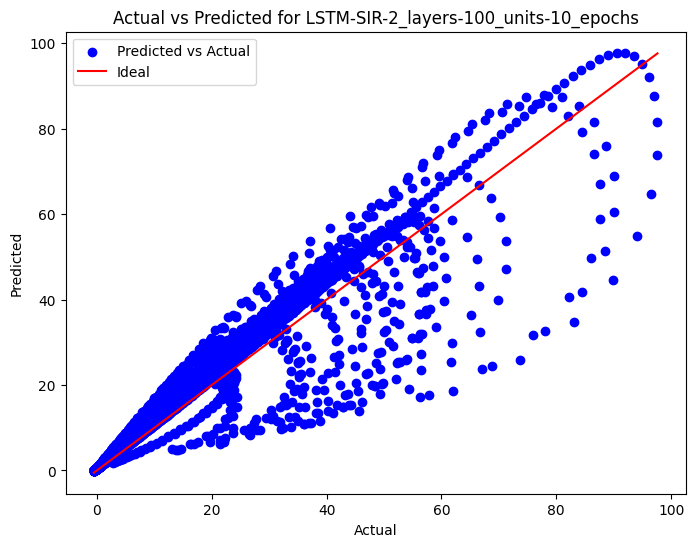

In [78]:
# Now, we can load the best model and plot its scatter
def plot_best_model_scatter(model_name, test_data_scaled, look_back, scalers):
    # Load the best model
    model = load_model(f'{model_name}/model_{model_name}.keras')

    # Make predictions for the entire test set
    predicted_series_list = []
    actual_series_list = []

    for i in range(test_data_scaled.shape[1]):
        test_series = test_data_scaled[:, i]
        X_test_i, y_test_i = create_sequences(test_series, look_back)
        X_test_i = X_test_i.reshape((X_test_i.shape[0], look_back, 1))

        # Predict
        predicted_test_i = model.predict(X_test_i)
        predicted_test_i_inverse = scalers[0].inverse_transform(predicted_test_i.reshape(-1, 1))
        y_test_i_inverse = scalers[0].inverse_transform(y_test_i.reshape(-1, 1))

        predicted_series_list.append(predicted_test_i_inverse)
        actual_series_list.append(y_test_i_inverse)

    # Flatten the predictions and actual values for scatter plotting
    predicted_flat = np.concatenate(predicted_series_list)
    actual_flat = np.concatenate(actual_series_list)

    # Plot the scatter plot for actual vs predicted
    plt.figure(figsize=(8, 6))
    plt.scatter(actual_flat, predicted_flat, color='blue', label='Predicted vs Actual')
    plt.plot([actual_flat.min(), actual_flat.max()], [actual_flat.min(), actual_flat.max()], color='red', label='Ideal')
    plt.title(f'Actual vs Predicted for {model_name}')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.legend()
    plt.show()

# Plot scatter for the best model
plot_best_model_scatter(best_model_name, test_data_scaled, look_back, scalers)